# Stage 6: Using the link

Three tests of what a delivered pair is good for, all run with finite measurement shots like a real experiment:

1. **CHSH (Bell test):** proves entanglement. Classical physics gives $S \le 2$; quantum allows up to $2\sqrt2 \approx 2.83$.
2. **Entanglement-based QKD (BBM92):** error rate and secret key.
3. **Teleportation:** sending an unknown qubit state.

Then **BB84** (prepare-and-measure QKD) with an eavesdropper, and a summary of the thresholds found across all stages.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qnet import physics as P, quantum as Q, plotstyle as S
S.apply()

## 1. CHSH test with finite shots

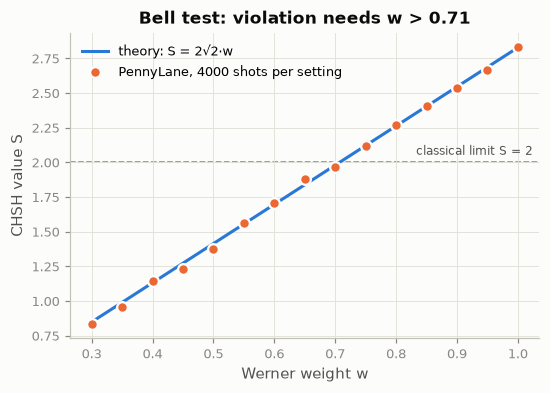

In [2]:
chsh = Q.make_link_circuit("chsh", shots=4000)
w_vals = np.linspace(0.3, 1, 15)
S_meas = [Q.chsh_from_terms(chsh(w)) for w in w_vals]
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(w_vals, 2 * np.sqrt(2) * w_vals, label="theory: S = 2√2·w")
ax.plot(w_vals, S_meas, "o", label="PennyLane, 4000 shots per setting", ms=7, mec="#fcfcfb", mew=1.5)
S.threshold(ax, 2, "classical limit S = 2")
ax.set(xlabel="Werner weight w", ylabel="CHSH value S", title="Bell test: violation needs w > 0.71")
ax.legend(loc="upper left")
S.save(fig, "06_chsh")

## 2. BBM92 QKD: measured error rate and key

In [3]:
samp = Q.make_link_circuit("samples_zz", shots=20000)
for w in [0.98, 0.9, 0.8, 0.75]:
    s = np.asarray(samp(w)); qz = np.mean(s[:, 0] != s[:, 1])
    print(f"w={w:.2f}: measured QBER {qz*100:5.2f}% (theory {(1-w)/2*100:5.2f}%), "
          f"secret key per sifted pair {Q.bbm92_key_fraction(qz, qz):.3f}")

w=0.98: measured QBER  0.97% (theory  1.00%), secret key per sifted pair 0.835
w=0.90: measured QBER  4.98% (theory  5.00%), secret key per sifted pair 0.401
w=0.80: measured QBER 10.42% (theory 10.00%), secret key per sifted pair 0.000
w=0.75: measured QBER 12.79% (theory 12.50%), secret key per sifted pair 0.000


## 3. Teleportation

Average fidelity over random input states, against pair fidelity. The best a classical scheme can do
(measure and describe the state) is 2/3, and theory for a Werner pair is $(2F + 1)/3$.

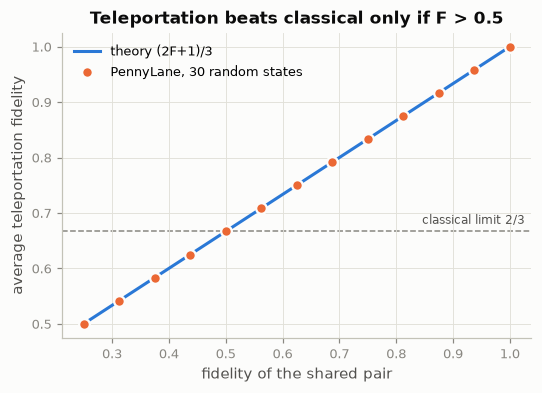

In [4]:
rng = np.random.default_rng(0)
states = [(np.arccos(1 - 2 * rng.random()), 2 * np.pi * rng.random()) for _ in range(30)]   # uniform on the Bloch sphere
F_pair = np.linspace(0.25, 1, 13)
F_tel = [np.mean([Q.teleport_fidelity(th, ph, (4 * F - 1) / 3) for th, ph in states]) for F in F_pair]
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(F_pair, (2 * F_pair + 1) / 3, label="theory (2F+1)/3")
ax.plot(F_pair, F_tel, "o", label="PennyLane, 30 random states", ms=7, mec="#fcfcfb", mew=1.5)
S.threshold(ax, 2 / 3, "classical limit 2/3")
ax.set(xlabel="fidelity of the shared pair", ylabel="average teleportation fidelity", title="Teleportation beats classical only if F > 0.5")
ax.legend(loc="upper left")
S.save(fig, "06_teleportation")

## 4. BB84 with an intercept-resend eavesdropper

Eve measures a fraction of photons in a random basis and resends what she saw. Each intercepted photon
causes an error 25% of the time after sifting, so QBER ≈ fraction/4. Eve's presence is revealed by the error rate.

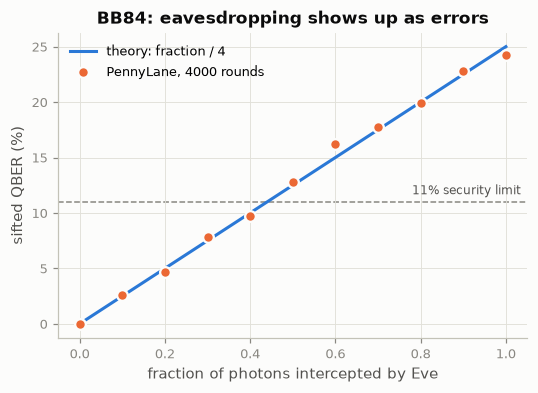

In [5]:
fr = np.linspace(0, 1, 11)
qb = [Q.bb84(4000, eve_fraction=f, seed=int(10 * f))["qber"] for f in fr]
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(fr, fr / 4 * 100, label="theory: fraction / 4")
ax.plot(fr, np.array(qb) * 100, "o", label="PennyLane, 4000 rounds", ms=7, mec="#fcfcfb", mew=1.5)
S.threshold(ax, 11, "11% security limit")
ax.set(xlabel="fraction of photons intercepted by Eve", ylabel="sifted QBER (%)", title="BB84: eavesdropping shows up as errors")
ax.legend(loc="upper left")
S.save(fig, "06_bb84_eve")

## Summary of thresholds

| Quantity | Threshold | Where it came from |
|---|---|---|
| Entanglement exists | F > 0.5 (w > 1/3) | Stages 1, 2 |
| Bell violation (CHSH) | w > 1/√2 ≈ 0.71 (F > 0.78) | Stage 6 |
| Secure QKD | QBER < ~11% (F > ~0.835) | Stages 1–6 |
| Teleportation beats classical | F > 0.5 | Stage 6 |

**Overall message.** Whether two nodes can share *usable* entanglement depends as much on the classical side
(timing precision, calibration, signalling delay, retry and purification policy) as on the quantum hardware.
That classical control plane is the natural next thing to study at network scale, for example in ns-3 with Q2NS.